In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler 
import tensorflow as tf
from tensorflow import keras 
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau 

In [31]:
from pathlib import Path
BASE_DIR = Path.cwd().parent
DATA_PATH = BASE_DIR/"data"/"processed"/"cleaned_housing.csv"
df = pd.read_csv(DATA_PATH)
print(df.shape)
print(df.head())

(20640, 10)
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  


In [32]:
X = df.drop("median_house_value", axis=1)
y=df["median_house_value"]
print(X.shape)
print(y.shape)

(20640, 9)
(20640,)


In [33]:
X = pd.get_dummies(X, columns=["ocean_proximity"], dtype=int)
print(X.shape)
print(X.head())

(20640, 13)
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  ocean_proximity_<1H OCEAN  \
0       322.0       126.0         8.3252                          0   
1      2401.0      1138.0         8.3014                          0   
2       496.0       177.0         7.2574                          0   
3       558.0       219.0         5.6431                          0   
4       565.0       259.0         3.8462                          0   

   ocean_proximity_INLAND  ocean_proximity_ISLAND  ocean_proximity_NEAR BAY  \
0                       0      

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)


(16512, 13)
(4128, 13)
(16512,)
(4128,)


In [35]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(16512, 13)
(4128, 13)


In [36]:
print(X_train_scaled[:2])

[[ 1.27258656 -1.3728112   0.34849025  0.22256942  0.21122752  0.76827628
   0.32290591 -0.326196   -0.89468316 -0.68057418 -0.01556621 -0.35564565
   2.62975816]
 [ 0.70916212 -0.87669601  1.61811813  0.34029326  0.59309419 -0.09890135
   0.6720272  -0.03584338 -0.89468316 -0.68057418 -0.01556621 -0.35564565
   2.62975816]]


In [37]:
model = Sequential()
# Hidden layer
model.add(Dense(128, activation="relu", input_shape=(X_train_scaled.shape[1],)))
model.add(Dense(64, activation="relu"))
model.add(Dense(1, activation="relu"))
model.summary()

c:\Users\Hp\Desktop\AI-House-Price-Prediction\venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,113 (39.50 KB)

 Trainable params: 10,113 (39.50 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)
print("Successful")

Successful


In [39]:
early_stopping = EarlyStopping(
    monitor="val_lose",
    patience=10,
    mode="min",
    restore_best_weights=True
)
reduce_lr=ReduceLROnPlateau(
    monitor="val_lose",
    patience=5,
    mode="min",
    min_lr=0.00001
)
print("Successfull")

Successfull


In [40]:
history = model.fit(
    X_train_scaled, 
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[
        early_stopping,
        reduce_lr
    ],
    verbose=1
)

Epoch 1/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 55653150720.0000 - mae: 205976.1250 - val_loss: 54737874944.0000 - val_mae: 203497.0625 - learning_rate: 0.0010
Epoch 2/100
  9/413 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 50191101952.0000 - mae: 198305.6406   

c:\Users\Hp\Desktop\AI-House-Price-Prediction\venv\Lib\site-packages\keras\src\callbacks\early_stopping.py:100: UserWarning: Early stopping conditioned on metric `val_lose` which is not available. Available metrics are: loss,mae,val_loss,val_mae
  current = self.get_monitor_value(logs)
c:\Users\Hp\Desktop\AI-House-Price-Prediction\venv\Lib\site-packages\keras\src\callbacks\callback_list.py:171: UserWarning: Learning rate reduction is conditioned on metric `val_lose` which is not available. Available metrics are: loss,mae,val_loss,val_mae,learning_rate.
  callback.on_epoch_end(epoch, logs)


413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 48608030720.0000 - mae: 190778.7031 - val_loss: 41553604608.0000 - val_mae: 174017.0469 - learning_rate: 0.0010
Epoch 3/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 31311790080.0000 - mae: 146917.2031 - val_loss: 22436720640.0000 - val_mae: 119336.2266 - learning_rate: 0.0010
Epoch 4/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 16142369792.0000 - mae: 97991.4375 - val_loss: 12513352704.0000 - val_mae: 84283.0391 - learning_rate: 0.0010
Epoch 5/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 10678849536.0000 - mae: 79041.1641 - val_loss: 10063844352.0000 - val_mae: 75173.6562 - learning_rate: 0.0010
Epoch 6/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 9220792320.0000 - mae: 72698.6406 - val_loss: 9038694400.0000 - val_mae: 70695.6797 - learning_rate: 0.0010
Epoch 7/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 8398085120.0000 - mae: 68457.5391 - val_loss: 8296309248.0000 - val_mae: 67096.6875 - learning

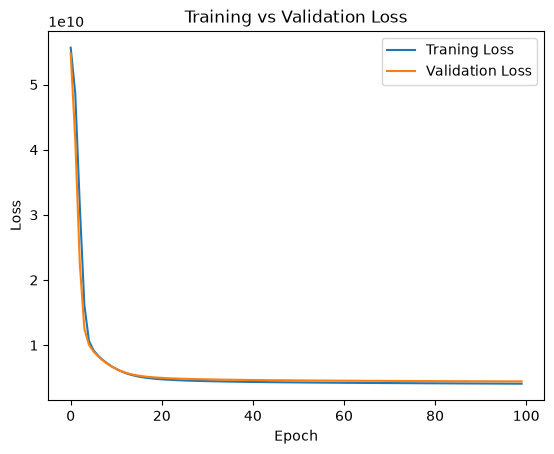

In [41]:
# plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"],
    label="Traning Loss"
)
plt.plot(history.history["val_loss"],
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

In [42]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
#Prediction
y_pred= model.predict(X_test_scaled ).flatten()

mae=mean_absolute_error(y_test, y_pred)
rmse=np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(mae)
print(rmse)
print(r2)

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
46749.520969072975
66131.98687584544
0.6662538367206609


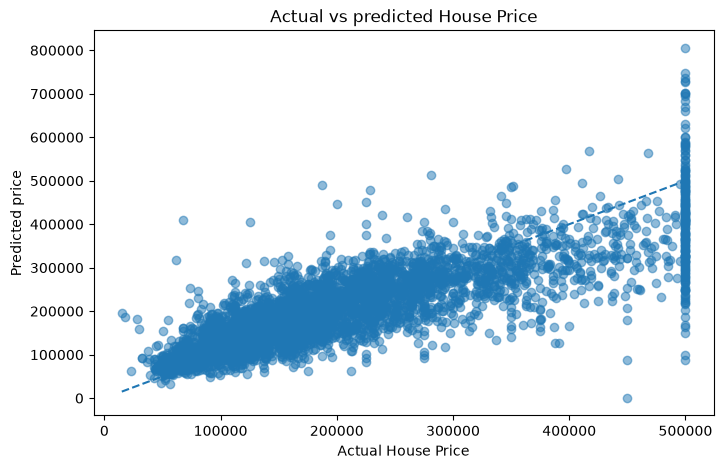

In [43]:
plt.figure(figsize=(8, 5))
plt.scatter(
    y_test,
    y_pred,
     alpha=0.5
)
plt.xlabel("Actual House Price")
plt.ylabel("Predicted price")
plt.title("Actual vs predicted House Price")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],    
    linestyle="--",
    
)
plt.show()


In [44]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)

# Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

# Gradient Boosting
gb_model = GradientBoostingRegressor(
    random_state=42
)
gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)

# Results function
def get_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)
    return mae, rmse, r2

lr_mae, lr_rmse, lr_r2 = get_metrics(y_test, lr_pred)
rf_mae, rf_rmse, rf_r2 = get_metrics(y_test, rf_pred)
gb_mae, gb_rmse, gb_r2 = get_metrics(y_test, gb_pred)

print("Linear Regression:", lr_mae, lr_rmse, lr_r2)
print("Random Forest:", rf_mae, rf_rmse, rf_r2)
print("Gradient Boosting:", gb_mae, gb_rmse, gb_r2)
print("ANN:", mae, rmse, r2)

Linear Regression: 50670.738240971914 70060.5218447352 0.6254240620553604
Random Forest: 31636.19363129845 48977.751228334 0.8169411111174801
Gradient Boosting: 38249.308474389705 55878.16951744344 0.7617255467211747
ANN: 46749.520969072975 66131.98687584544 0.6662538367206609


In [45]:
comparision = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting",
         "ANN"
    ],
    "R2 Score":[
        lr_model,
        rf_model,
        gb_model,
        r2        
    ],
    "MAE":[
        lr_mae,
        rf_mae,
        gb_mae,
        mae
    ],
    "RMSE":[
        lr_rmse,
        rf_rmse,
        gb_rmse,
        rmse
    ]
})
print(comparision)

               Model                                           R2 Score  \
0  Linear Regression                                 LinearRegression()   
1      Random Forest  (DecisionTreeRegressor(max_features=1.0, rando...   
2  Gradient Boosting  ([DecisionTreeRegressor(max_depth=3,\n        ...   
3                ANN                                           0.666254   

            MAE          RMSE  
0  50670.738241  70060.521845  
1  31636.193631  48977.751228  
2  38249.308474  55878.169517  
3  46749.520969  66131.986876  


In [46]:
from pathlib import Path
BASE_DIR =Path.cwd().parent
MODEL_PATH =BASE_DIR/"models"/"ann_house_price_model.keras"
model.save(MODEL_PATH)
print(MODEL_PATH)

c:\Users\Hp\Desktop\AI-House-Price-Prediction\models\ann_house_price_model.keras


In [47]:
import joblib
from pathlib import Path

BASE_DIR = Path.cwd().parent

SCALER_PATH = BASE_DIR / "models" / "ann_scaler.pkl"

joblib.dump(scaler, SCALER_PATH)

print("ANN scaler saved successfully!")
print("Scaler path:", SCALER_PATH)

ANN scaler saved successfully!
Scaler path: c:\Users\Hp\Desktop\AI-House-Price-Prediction\models\ann_scaler.pkl


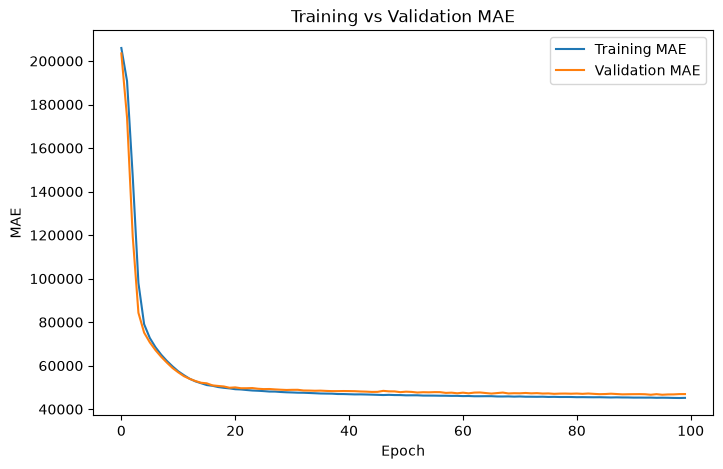

In [48]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["mae"],
    label="Training MAE"
)

plt.plot(
    history.history["val_mae"],
    label="Validation MAE"
)

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Training vs Validation MAE")

plt.legend()
plt.show()

In [49]:
from tensorflow import keras
from pathlib import Path

BASE_DIR = Path.cwd().parent

MODEL_PATH = BASE_DIR / "models" / "ann_house_price_model.keras"

loaded_model = keras.models.load_model(MODEL_PATH)

y_pred_loaded = loaded_model.predict(X_test_scaled).flatten()

print("ANN model loaded successfully!")
print("Sample prediction:", y_pred_loaded[0])

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
ANN model loaded successfully!
Sample prediction: 67394.43


## Predict Fuction

In [50]:
def predict_house_price(input_data):
    """
    Predict house price using the trained ANN model.
    """
    
    prediction = loaded_model.predict(input_data, verbose=0)

    return prediction[0][0]


# Test prediction
sample_data = X_test_scaled[0].reshape(1, -1)

predicted_price = predict_house_price(sample_data)

print("Predicted House Price:", predicted_price)

Predicted House Price: 67394.445


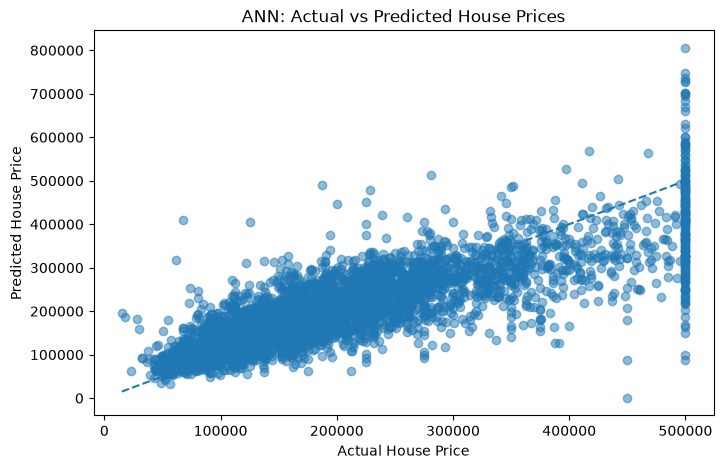

In [51]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("ANN: Actual vs Predicted House Prices")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)